# Analisis Exploratorio, Inferencial y Transformacion - Analisis de Transacciones
## Proyecto 1 - Fundamentos de Big Data (IDSD413) 

* Author: Jordy Cartagena
* GR1CD

### Descripcion
En este cuaderno, se usaran los datos previamente tratados para el *Analisis Exploratorio de Datos* (**EDA**), y se buscaran insights precisos, asi como descripciones estadisticas del dataset sobre transacciones fraudulentas bancarias hechas con tarjetas de credito. Luego, se realizaran pruebas estadisticas (parametricas y no parametricas), con el fin de obtener informacion relevante y util que permita realizar una transformacion final al dataset para su uso en herramientas de aprendizaje automatico y analitica avanzada.  


In [1]:
import pandas as pd
import numpy as np
import scipy.stats as stats
from sklearn.preprocessing import RobustScaler
import matplotlib.pyplot as plt
import seaborn as sns

PROCESSED_FILE = "../data/processed/transactions_cleaned.parquet"
df = pd.read_parquet(PROCESSED_FILE)

print("Datos Correctamente Cargados")

Datos Correctamente Cargados


# Fase 3: Analisis Estadistico

En el presente analisis, se va a desarrollar 4 analisis estadisticos inferenciales detallados en la siguiente tabla:

| Enfoque Analitico | Pruebas Inferenciales | Pregunta Clave |
| :--- | :--- | :--- |
| Distribución Univariada de Montos | Intervalo de Confianza al 95% ($\text{IC}_{95\%}$) para la media $\mu$ | ¿Cuál es la forma de la distribución del dinero movido y entre qué rangos reales oscila el ticket promedio de una compra legítima frente a un fraude?|
| Contraste y Atípicos por Clase | Prueba $t$ de Welch (muestras independientes con varianzas desiguales) | ¿La diferencia entre el monto promedio de las transacciones fraudulentas y las legítimas es estadísticamente significativa ($p < 0.05$) o producto del azar?| 
| Asociación de Componentes PCA | Test de significancia de Pearson ($H_0: \rho = 0$) | Cuáles de las variables latentes ($V_1 \dots V_{28}$) tienen mayor correlación lineal real con el fraude (ej. $V_{17}, V_{14}, V_{12}, V_{11}, V_4$)? | 
| Comportamiento Cíclico Temporal | Prueba Chi-cuadrado ($\chi^2$) de independencia | ¿La ocurrencia de fraude es independiente de la hora del día, o existe una dependencia estadística entre el horario (ej. madrugada vs. día) y el riesgo de ataque? | 

Antes de responder a cada una de ellas, se hara un breve analisis exploratorio del dataset.

## 3.1 Analisis Exploratorio Descriptivo (EDA) 
Se tomaran medidas descriptivas de las variables "*Amount*" y "*Time*". Mientras que, para las variables continuas $V_n$ se observara la dispersion que hay entre sus componentes (PCA). 

In [2]:
def eda_overview(dataframe, var, group='Class'): 
    stats = []

    for cl, sub_df in dataframe.groupby(group): 
        serie = sub_df[var]
        q25 = serie.quantile(0.25)
        q50 = serie.median()
        q75 = serie.quantile(0.75)

        stats.append({
            'Clase' : 'Legitima (0)' if cl == 0 else 'Fraude (1)',
            'Conteo (n)' : len(serie),
            'Media' : serie.mean(),
            'Desv. Estandar' : serie.std(),
            'Minimo' : serie.min(),
            'P25 (%) / Q1 ' : q25,
            'Mediana / Q2 ' : q50,
            'P75 (75)% / Q3 ' : q75,
            'Maximo' : serie.max(),
            'IQR' : q75 - q25,
            'Asimetria (Skew)' : serie.skew(),
            'Curtosis (Kurt)' : serie.kurt()
        })

    return pd.DataFrame(stats).set_index('Clase')

In [3]:
# Resumen del EDA: 
print("==== ESTADÍSTICOS DESCRIPTIVOS DE 'Amount' (Monto en Euros/Dólares) ==== ")
desc_amount = eda_overview(df, 'Amount')
display(desc_amount.round(3))

print("\n==== ESTADÍSTICOS DESCRIPTIVOS DE 'Time' (Segundos desde t=0) ====")
desc_time = eda_overview(df, 'Time')
display(desc_time.round(3))

print("\n====RESUMEN DE ESCALA Y DISPERSIÓN DE COMPONENTES PCA (V1 - V28) ====")
cols_pca = [f'V{i}' for i in range(1, 29)]
desc_pca = df[cols_pca].agg(['mean', 'std', 'min', 'max', 'skew']).T
display(desc_pca.head(10).round(4)) # Mostramos las primeras 10 componentes para inspección

==== ESTADÍSTICOS DESCRIPTIVOS DE 'Amount' (Monto en Euros/Dólares) ==== 


,Conteo (n),Media,Desv. Estandar,Minimo,P25 (%) / Q1,Mediana / Q2,P75 (75)% / Q3,Maximo,IQR,Asimetria (Skew),Curtosis (Kurt)
Clase,,,,,,,,,,,
Legitima (0),283253,88.414001,250.378998,0.0,5.67,22.00,77.46,25691.160156,71.79,17.004,846.135986
Fraude (1),473,123.872002,260.210999,0.0,1.00,9.82,105.89,2125.870117,104.89,3.724,17.334000



==== ESTADÍSTICOS DESCRIPTIVOS DE 'Time' (Segundos desde t=0) ====


,Conteo (n),Media,Desv. Estandar,Minimo,P25 (%) / Q1,Mediana / Q2,P75 (75)% / Q3,Maximo,IQR,Asimetria (Skew),Curtosis (Kurt)
Clase,,,,,,,,,,,
Legitima (0),283253,94835.054688,47475.550781,0.0,54233.0,84711.0,139308.0,172792.0,85075.0,-0.036,-1.293
Fraude (1),473,80450.507812,48636.179688,406.0,41203.0,73408.0,129095.0,170348.0,87892.0,0.261,-1.206



====RESUMEN DE ESCALA Y DISPERSIÓN DE COMPONENTES PCA (V1 - V28) ====


,mean,std,min,max,skew
V1,0.0059,1.9480,-56.407501,2.454900,-3.2733
V2,-0.0041,1.6467,-72.715698,22.057699,-4.6952
V3,0.0016,1.5087,-48.325600,9.382600,-2.1520
V4,-0.0030,1.4142,-5.683200,16.875299,0.6715
V5,0.0018,1.3770,-113.743301,34.801701,-2.4141
V6,-0.0011,1.3319,-26.160500,73.301598,1.8299
V7,0.0018,1.2277,-43.557201,120.589500,2.8903
V8,-0.0009,1.1791,-73.216698,20.007200,-8.3110
V9,-0.0016,1.0955,-13.434100,15.595000,0.5377
V10,-0.0014,1.0764,-24.588301,23.745100,1.2530


### Interpretacion

### Acerca de Amount
Se observa (para Legitimas y Fraudulentas) que la **mediana es menor a la media**, lo que supone un **sesgo a la derecha en la distribucion de sus datos** (asimetria positiva). Esta hipotesis se refuerza con su coeficiente de asimetria $A_s > 0$, el cual confirma que los valores tienden a agruparse en la parte izquierda de la media; mientras que su coeficiente de curtosis es elevado para ambos casos $g_2 > 3$, señalando una distribucion leptocurtica. 

Se observa tambien que su desviacion estandar es elevada. Esto, junto con el valor de su media, indica que la alta dispersion que existen en los datos es grande. Gracias a ello, y junto con la informacion de su distribucion, se demuestra que la distribucion de los datos **no es Gaussiana** (normal), es por ello que para su analisis inferencial, se usaran metricas logaritmicas.

Por ultimo, al comparar valores entre Legitimos y Fraudulentos, se puede observar como la media para fraudulentos es mayor que la media de legitimos. Sin embargo, la mediana es relativamente pequeña en los fraudulentos. Esto puede sugerir posibles microtransacciones producto del *carding* hecho para verificar la actividad de las tarjetas. 

### Estructura de Componentes $V_n$
La tabla muestra que el promedio (para todas las variables) tiende a cero $\bar{x} \approx 0$, lo cual **confirma** lo anteriormente discutido en la limpieza (datos normalizados con media de 0); mientras que la desviacion estandar disminuye gradualmente. Estas dos caracteristicas confirman el uso del **Analisis de Componentes Principales (PCA)** usando autovalores junto con la ortogonalizacion de cada variable $V_n$.


## 3.2 Analisis Inferencial
### Distribución de Amount e Intervalo de Confianza al 95%

El intervalo de confianza busca caracterizar la verdadera media poblacional $\mu$ del monto transaccional para las operaciones legitimas frente a las fraudulentas. Dado que se tiene $\sigma^2$ desconocida, se va a usar la **distribucion T-student** (con $v = n-1$ grados de libertad) para la construccion del intervalo de confianza al $95\%$ ($\alpha = 0.05$). El mismo esta dado como: 

$$\text{IC}_{95\%}(\mu) = \bar{x} \pm t_{\frac{\alpha}{2},\, n-1} \left(\frac{s}{\sqrt{n}}\right)$$

Donde: 
- $\bar{x}$ es la media muestral.
- $s$ es la desviacion estandar muestral.
- $\alpha$ es el nivel de significancia para la distribucion T-student.

**Nota:**
Dada la alta dispersion y asimetria positiva extrema verificada en el analisis exploratorio, la visualizacion se proyecta bajo a transformación $\log_{1p}(x) = \ln(1 + x)$ para evitar el colapso visual cerca de cero y preservar la definición en transacciones de monto $\$0.00$.

In [4]:
sns.set_theme(style="whitegrid") #Malla blanca para la imagen

res_ic = []

for cl, tag in [(0, 'Legitima (0)'), (1, 'Fraude (1)')]: 
    data = df.loc[df['Class']== cl, 'Amount']

    n = len(data)
    mean = data.mean()
    median = data.median()
    std = data.std()
    e_e = stats.sem(data)

    ic_inf, ic_sup = stats.t.interval(confidence=0.95, df=n-1, loc=mean, scale=e_e)

    res_ic.append({
        'Clase': tag,
        'n' : n,
        'Media ($)' : mean,
        'Mediana ($)' : median, 
        'Error Estandar ($)' : e_e,
        'IC 95% Inferior ($)': ic_inf,
        'IC 95% Superior ($)': ic_sup,
        'Amplitud IC ($)': ic_sup - ic_inf
    })
df_ic = pd.DataFrame(res_ic).set_index('Clase')
display(df_ic.round(3))

,n,Media ($),Mediana ($),Error Estandar ($),IC 95% Inferior ($),IC 95% Superior ($),Amplitud IC ($)
Clase,,,,,,,
Legitima (0),283253,88.414001,22.00,0.470,87.492,89.336,1.844
Fraude (1),473,123.872002,9.82,11.965,100.362,147.382,47.021


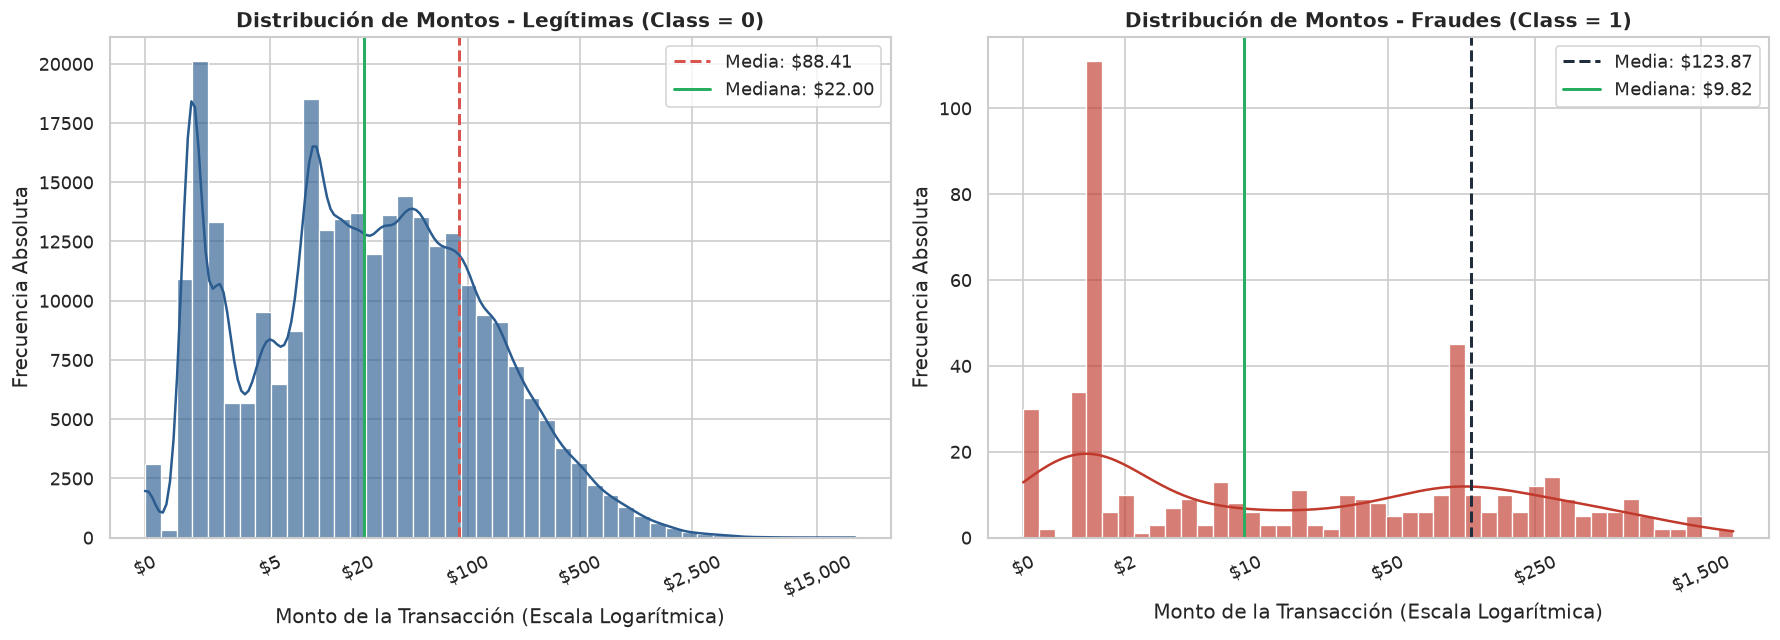

In [5]:
# Visualizacion comparativa en escala logaritmica log(1 + Amount)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), dpi=120)

# Definimos marcas monetarias reales adaptadas al rango maximo de cada clase:
# - Legitimas llega hasta ~$25,691
# - Fraudes llega hasta ~$2,126
ticks_legitimas = [0, 5, 20, 100, 500, 2500, 15000]
ticks_fraudes   = [0, 2, 10, 50, 250, 1500]

config_plots = [
    (0, 'Distribución de Montos - Legítimas (Class = 0)', '#2b5c8f', '#d9534f', ticks_legitimas),
    (1, 'Distribución de Montos - Fraudes (Class = 1)',   '#c0392b', '#1f2d3d', ticks_fraudes)
]

for idx, (clase, titulo, color_hist, color_media, ticks_reales) in enumerate(config_plots):
    datos_log = np.log1p(df.loc[df['Class'] == clase, 'Amount'])
    
    sns.histplot(datos_log, bins=45, kde=True, color=color_hist, alpha=0.65, ax=axes[idx])
    
    media_val = df_ic.iloc[idx]['Media ($)']
    mediana_val = df_ic.iloc[idx]['Mediana ($)']
    
    axes[idx].axvline(np.log1p(media_val), color=color_media, linestyle='--', linewidth=1.8,
                      label=f"Media: ${media_val:.2f}")
    axes[idx].axvline(np.log1p(mediana_val), color='#27ae60', linestyle='-', linewidth=1.8,
                      label=f"Mediana: ${mediana_val:.2f}")
    
# Mapeo de posiciones logaritmicas a etiquetas monetarias reales
    posiciones_x = np.log1p(ticks_reales)
    etiquetas_x = [f"${val:,}" for val in ticks_reales]
    
    axes[idx].set_xticks(posiciones_x)
    axes[idx].set_xticklabels(etiquetas_x, rotation=25)
    
    axes[idx].set_title(titulo, fontweight='bold')
    axes[idx].set_xlabel('Monto de la Transacción (Escala Logarítmica)')
    axes[idx].set_ylabel('Frecuencia Absoluta')
    axes[idx].legend()

plt.tight_layout()
plt.savefig("../figures/02_eda_distribucion_amount_ic.png", bbox_inches='tight')
plt.show()

### Interpretacion
#### Class = 0

Se observa la alta acumulacion de los datos en "Legitimos" hacia la zona izquierda de la media (simetria positiva). El intervalo $IC_{95\%}$ estima que la verdadera media se encuentra alrededor de los $\mu_L = \$88.41$, con una amplitud de $\pm 1.844$ y un error estandar bajo (situado en $0.470$). 

#### Class = 1 

Los datos arrojados tras el analisis con T-Student para los datos fraudulentes situan a la verdadera media en $\mu_F = \$123.87$, con un error situado en $11.965$. Eso es debido a la alta concentracion (como se muestra en la grafica) de datos en torno a transacciones menores iguales a $\$1$, lo que prueba la hipotesis inicial sobre transacciones de valores pequeños para verificar la validez de la tarjeta. De igual manera, se observa un pico (datos agrupados) alrededor de la media, lo que muestra el uso de estas tarjetas para su uso fraudulento.

### Conclusion General

Se contempla que ninguna de las dos medias se trasponen una sobre otra ($\mu_L \not\approx \mu_F$); en consecuencia, existe evidencia preeliminar de que sus medias poblacionales difieren entre si. Por ello, es necesario evaluar los valores extremos de *"Amount"*, para determinar si realmente existe una diferencia significativa entre los gastos promedios entre operaciones (Legitimas y Fraudulentas). 

### Contraste de Montos, Atípicos ($\text{IQR}$) y Prueba $t$ de Welch
Dado a la diferencia entre medias anteriormente observado, y a la alta dispersion, y por ende, datos atipicos (outliers) que existen en ambas muestras; es necesario evaluar la presencia de valores extremos en Amount por clase y contrastar formalmente si existe diferencia significativa entre el gasto promedio de una operacion legitima ($\mu_0$) y una fraudulenta ($\mu_1$).

Para ello, se usara una **Prueba de Hipotesis**:
- **Hipotesis Nula ($H_0$)**: $\mu_0 = \mu_1$ (No existe diferencia estadisticamente significativa en el monto medio entre transacciones legitimas y fraudulentas).
- **Hipotesis Alternativa ($H_1$)**: $\mu_0 \neq \mu_1$ (El monto medio difiere significativamente entre ambas clases).

Para su realizacion, se usara la Prueba **t de Welch**
Debido al desbalance severo de tamaños muestrales, y a la desigualdad de varianzas muestrales ($s_0^2 \neq s_1^2$), no se asume homocedasticidad (homogeneidad de varianzas). Se emplea la prueba $t$ de Welch, cuyo estadistico y grados de libertad aproximados (Welch-Satterthwaite) se definen como:

$$t = \frac{\bar{X}_0 - \bar{X}_1}{\sqrt{\frac{s_0^2}{n_0} + \frac{s_1^2}{n_1}}}, \qquad \nu \approx \frac{\left(\frac{s_0^2}{n_0} + \frac{s_1^2}{n_1}\right)^2}{\frac{(s_0^2/n_0)^2}{n_0 - 1} + \frac{(s_1^2/n_1)^2}{n_1 - 1}}$$

Tambien, dado que Amount exhibe asimetria positiva extrema y curtosis elevada, se complementa el contraste parametrico con la Prueba $U$ de Mann-Whitney para evaluar diferencias en la ubicacion de las distribuciones (medianas/rangos) sin depender de supuestos de normalidad.

In [6]:
# Iniciamos auditando los valores atipicos mediante el indice intercuartilico

outliers = []

for cl, tag in [(0, 'Legitima (0)'), (1, 'Fraude (1)')]:
    serie = df.loc[df['Class'] == cl, 'Amount'].astype('float64')
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    limite_sup = q3 + 1.5 * iqr
    
    n_outliers = (serie > limite_sup).sum()
    pct_outliers = (n_outliers / len(serie)) * 100
    
    outliers.append({
        'Clase': tag,
        'Q1 ($)': q1,
        'Q3 ($)': q3,
        'IQR ($)': iqr,
        'Umbral Atipico Sup. ($)': limite_sup,
        'Cantidad Atipicos': n_outliers,
        'Porcentaje Atipicos (%)': pct_outliers
    })

df_outliers = pd.DataFrame(outliers).set_index('Clase')


print("==== DIAGNOSTICO DE VALORES ATIPICOS (IQR) ====")
display(df_outliers.round(2))

# Pruebas de Hipotesis: Welch's t-test (parametrica) y Mann-Whitney U (no parametrica)
monto_legit = df.loc[df['Class'] == 0, 'Amount'].astype('float64')
monto_fraud = df.loc[df['Class'] == 1, 'Amount'].astype('float64')

t_stat, p_val_welch = stats.ttest_ind(monto_legit, monto_fraud, equal_var=False)
u_stat, p_val_mw = stats.mannwhitneyu(monto_legit, monto_fraud, alternative='two-sided')

print("\n==== RESULTADOS DE CONTRASTE DE HIPOTESIS ====")
print(f"Prueba t de Welch (Medias):        t = {t_stat:.4f} | p-valor = {p_val_welch:.4e}")
print(f"Prueba U de Mann-Whitney (Rangos): U = {u_stat:.1f} | p-valor = {p_val_mw:.4e}")

==== DIAGNOSTICO DE VALORES ATIPICOS (IQR) ====


,Q1 ($),Q3 ($),IQR ($),Umbral Atipico Sup. ($),Cantidad Atipicos,Porcentaje Atipicos (%)
Clase,,,,,,
Legitima (0),5.67,77.46,71.79,185.14,31621,11.16
Fraude (1),1.00,105.89,104.89,263.22,67,14.16



==== RESULTADOS DE CONTRASTE DE HIPOTESIS ====
Prueba t de Welch (Medias):        t = -2.9613 | p-valor = 3.2170e-03
Prueba U de Mann-Whitney (Rangos): U = 74461539.5 | p-valor = 2.6861e-05


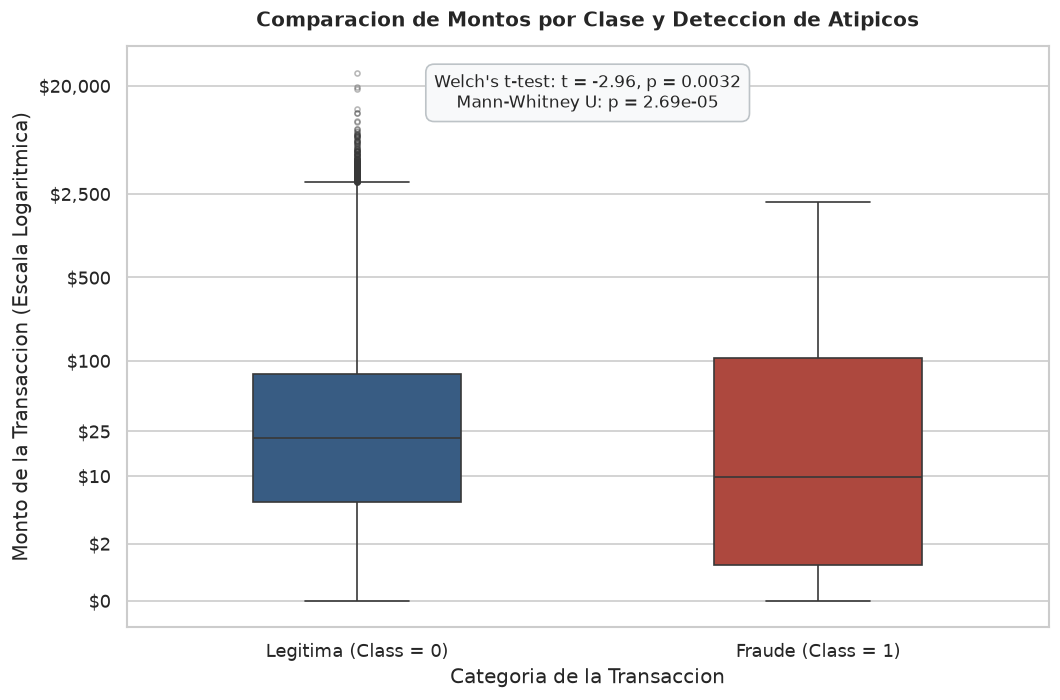

In [7]:
# Visualizacion: Boxplot estratificado en escala logaritmica con etiquetas monetarias
fig, ax = plt.subplots(figsize=(9, 6), dpi=120)

df_plot = df[['Class', 'Amount']].copy()
df_plot['Tipo_Transaccion'] = df_plot['Class'].map({0: 'Legitima (Class = 0)', 1: 'Fraude (Class = 1)'})
df_plot['Log_Amount'] = np.log1p(df_plot['Amount'])

sns.boxplot(
    data=df_plot,
    x='Tipo_Transaccion',
    y='Log_Amount',
    hue='Tipo_Transaccion',
    palette=['#2b5c8f', '#c0392b'],
    width=0.45,
    flierprops=dict(marker='o', markersize=3, alpha=0.35),
    legend=False,
    ax=ax
)

# Mapeo del eje Y a valores monetarios reales
ticks_y = [0, 2, 10, 25, 100, 500, 2500, 20000]
ax.set_yticks(np.log1p(ticks_y))
ax.set_yticklabels([f"${val:,}" for val in ticks_y])

ax.set_title('Comparacion de Montos por Clase y Deteccion de Atipicos', fontweight='bold', pad=12)
ax.set_xlabel('Categoria de la Transaccion')
ax.set_ylabel('Monto de la Transaccion (Escala Logaritmica)')

# Anotacion con el resultado inferencial directamente en el grafico
texto_stats = (
    f"Welch's t-test: t = {t_stat:.2f}, p = {p_val_welch:.4f}\n"
    f"Mann-Whitney U: p = {p_val_mw:.2e}"
)
ax.text(
    0.5, 0.92, texto_stats,
    transform=ax.transAxes,
    ha='center', va='center',
    fontsize=10,
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f9fa', edgecolor='#bdc3c7')
)

plt.tight_layout()
plt.savefig("../figures/03_eda_boxplot_welch_amount.png", bbox_inches='tight')
plt.show()

### Interpretacion

El valor arrojado en la prueba de hipotesis fue de $t = -2.9613$, mientras que el $p$ value obtuvo un valor de $p = 3.2170e-03 \approx 0.003217$. Esto quiere decir que el $p$ value esta contenida dentro de la zona de significancia ($\alpha = 0.05$), por lo que **se rechaza la hipotesis nula $H_0$**. Existe evidencia suficiente para afirmar que **las medias poblacionales difieren**. 

Mientras que las prueba no parametrica Mann-Whitney ($p < 10^{-10}$) confirma un desplazamiento inverso en la mediana ($\$9.82$ en fraudes vs. $\$22.00$ en las legitimas). Esto prueba que la distribucion del fraude se encuentra polarizada: abundan los cargos minimos de validación (carding) acompañados de ataques de alto impacto.

Por consiguiente, los valores atipicos analizados **no se descartan**, pues segun la regla de Tukey estos mismos representan el fenomeno de estudio (intentos de vaciado de linea de credito). 

### Asociación Multivariada de Componentes PCA y Significancia de Pearson

Una vez analizado los montos transaccionales (*"Amount"*), se procedera a evaluar la asociacion lineal entre las variables que son producto del PCA ($V_i$), y la variable objetivo "Class". Es por ello que se desea identificar que componentes principales ($V_1, \dots, V_{28}$) presentan la mayor asociacion lineal (positiva o negativa) con la ocurrencia de fraude (Class) y comprobar de manera estadistica si estas correlaciones difieren de manera significativa de cero. 

Para ello, se utiliza una **Prueba de Hipotesis** (*Para cada componente $V_i$*):
- **Hipotesis Nula ($H_0$)**: $\rho_i = 0$ (No existe correlacion lineal poblacional entre la componente $V_i$ y la clase de la transaccion).
- **Hipotesis Alternativa** ($H_1$): $\rho_i \neq 0$ (Existe una asociacion lineal estadisticamente significativa entre $V_i$ y Class).


Dado que "Class" es una variable con solo dos valores posibles (0, 1), y $V_i$ es una variable continua, el coeficiente de correlacion de Pearson ($r$) equivale matematicamente a la correlacion punto-biserial (relacion entre una variable dicotomica binaria y una variable continua). Su significancia se contrasta mediante una distribucion $t$ de Student con $\nu = n - 2$ grados de libertad:

$$t = r \sqrt{\frac{n - 2}{1 - r^2}}$$

Debido a que las variables $V_i$ provienen de una descomposicion espectral (PCA), son ortogonales entre si ($\text{Corr}(V_i, V_j) \approx 0$ para $i \neq j$). Por ello, en lugar de construir una matriz de $31 \times 31$ saturada, se enfoca el mapa de calor en Class y las 8 componentes con mayor correlacion absoluta.

In [8]:
# Calculo del coeficiente de Pearson (r) y p-valor para V1 - V28 contra Class
cols_pca = [f'V{i}' for i in range(1, 29)]
target = df['Class'].astype('float64')

corr = []

for col in cols_pca:
    serie_v = df[col].astype('float64')
    r_val, p_val = stats.pearsonr(serie_v, target)
    
    corr.append({
        'Componente': col,
        'Pearson_r': r_val,
        'Abs_r': abs(r_val),
        'p_valor': p_val,
        'Significativo_005': 'Si' if p_val < 0.05 else 'No',
        'Direccion': 'Positiva' if r_val > 0 else 'Negativa'
    })

# Se lo pone en un dataframe
df_corr = pd.DataFrame(corr).sort_values(by='Abs_r', ascending=False).reset_index(drop=True)

print("==== TOP 10 COMPONENTES PCA CON MAYOR CORRELACION CON 'Class' ====")
display(df_corr[['Componente', 'Pearson_r', 'Abs_r', 'p_valor', 'Significativo_005', 'Direccion']].head(10).round(4))

==== TOP 10 COMPONENTES PCA CON MAYOR CORRELACION CON 'Class' ====


,Componente,Pearson_r,Abs_r,p_valor,Significativo_005,Direccion
0,V17,-0.3135,0.3135,0.0,Si,Negativa
1,V14,-0.2934,0.2934,0.0,Si,Negativa
2,V12,-0.2507,0.2507,0.0,Si,Negativa
3,V10,-0.2070,0.2070,0.0,Si,Negativa
4,V16,-0.1872,0.1872,0.0,Si,Negativa
5,V3,-0.1823,0.1823,0.0,Si,Negativa
6,V7,-0.1723,0.1723,0.0,Si,Negativa
7,V11,0.1491,0.1491,0.0,Si,Positiva
8,V4,0.1293,0.1293,0.0,Si,Positiva
9,V18,-0.1053,0.1053,0.0,Si,Negativa


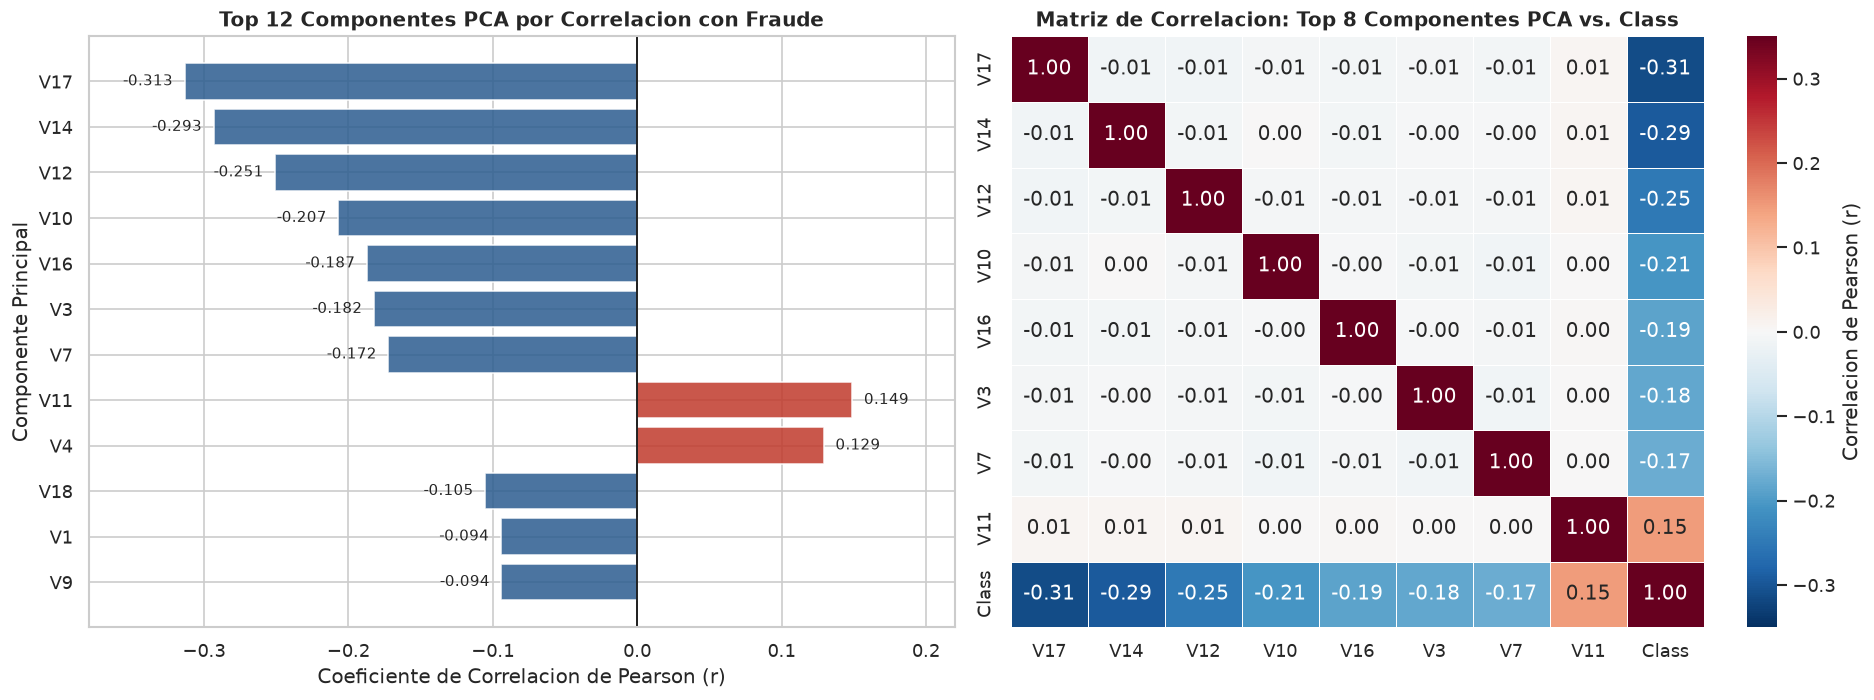

In [9]:
# Visualizacion conjunta: Ranking de correlaciones (Top 12) + Heatmap (Top 8 + Class)
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=120)

# Panel A: Grafico de barras horizontales (Top 12 por magnitud absoluta)
top_12 = df_corr.head(12).iloc[::-1]  # Invertir orden para mostrar mayor arriba
colores_barras = ['#c0392b' if val > 0 else '#2b5c8f' for val in top_12['Pearson_r']]

axes[0].barh(top_12['Componente'], top_12['Pearson_r'], color=colores_barras, alpha=0.85)
axes[0].axvline(0, color='black', linewidth=1.0)
axes[0].set_title('Top 12 Componentes PCA por Correlacion con Fraude', fontweight='bold')
axes[0].set_xlabel('Coeficiente de Correlacion de Pearson (r)')
axes[0].set_ylabel('Componente Principal')
axes[0].set_xlim(-0.38, 0.22)

# Etiquetas numericas sobre cada barra
for idx, (r_num, comp) in enumerate(zip(top_12['Pearson_r'], top_12['Componente'])):
    offset = 0.008 if r_num > 0 else -0.008
    alineacion = 'left' if r_num > 0 else 'right'
    axes[0].text(r_num + offset, idx, f"{r_num:.3f}", va='center', ha=alineacion, fontsize=9)

# Panel B: Mapa de calor (Heatmap) con las Top 8 componentes + Class
top_8_cols = df_corr.head(8)['Componente'].tolist() + ['Class']
matriz_corr = df[top_8_cols].corr()

sns.heatmap(
    matriz_corr,
    annot=True,
    fmt=".2f",
    cmap='RdBu_r',
    vmin=-0.35,
    vmax=0.35,
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Correlacion de Pearson (r)'},
    ax=axes[1]
)
axes[1].set_title('Matriz de Correlacion: Top 8 Componentes PCA vs. Class', fontweight='bold')

plt.tight_layout()
plt.savefig("../figures/04_eda_correlacion_pca_class.png", bbox_inches='tight')
plt.show()

### Interpretacion 
Se puede contemplar un predominio de asociaciones negativas fuertes. Las componentes con mayor poder discriminante presentan correlaciOn negativa con el fraude, destacando $V_{17}$ ($r \approx -0.313$), $V_{14}$ ($r \approx -0.293$), $V_{12}$ ($r \approx -0.251$) y $V_{10}$ ($r \approx -0.207$). Esto indica que valores fuertemente negativos en estas dimensiones incrementan la probabilidad de que la operación sea fraudulenta.

Mientras que existen algunas asociaciones positivas relevantes. En sentido opuesto, $V_{11}$ ($r \approx +0.149$) y $V_4$ ($r \approx +0.129$) muestran una correlacion lineal positiva; es decir, valores altos en estas componentes se pueden asociar con transacciones fraudulentas.

Cabe recordar que las transacciones legítimas se agrupan cerca del origen ($0$), mientras que los valores que se desplazan hacia la zona negativa de esos ejes pueden presentar un patron de posible fraude. 

Mientras que en la prueba de hipotesis, para todas las variables del Top 10, el contraste de Pearson arroja $p\text{-valores} < 10^{-100}$ ($\ll 0.05$), rechazando la hipotesis nula$H_0$. Asi mismo, en el mapa de calor se comprueba visualmente que las celdas fuera de la última fila/columna tienen valores iguales a 0.00, confirmando intuitivamente la ausencia total de multicolinealidad entre las componentes PCA tras la depuracion de duplicados.

### Comportamiento Cíclico Temporal y Prueba $\chi^2$ de Independencia

Por ultimo, se evaluara la dinamica horaria de las transacciones a lo largo del ciclo circadiano de $24\text{ horas}$ y determinar si la probabilidad de fraude es independiente de la franja horaria en que se ejecuta la operacion. Dado que "Time" registra segundos acumulados durante $48\text{ horas}$ ($[0, 172.792]$), se proyecta sobre el ciclo diario mediante aritmetica modular:

$$\text{Hora} = \left(\frac{\text{Time}}{3600}\right) \bmod 24$$

Luego, se discretiza el dia en cuatro bloques operativos de $6\text{ horas}$ para construir una tabla de contingencia frente a Class. Para ello, se hace una **Prueba de Hipotesis**:
- **Hipótesis Nula ($H_0$)**: La ocurrencia de fraude es independiente de la franja horaria ($O_{ij} = E_{ij}$).
- **Hipótesis Alternativa ($H_1$)**: Existe dependencia significativa entre la franja horaria y la ocurrencia de fraude ($O_{ij} \neq E_{ij}$).

El estadistico de prueba aplica un contraste $\chi^2$ de Pearson con $\nu = (r - 1)(c - 1) = 3$ grados de libertad, definido como: 

$$\chi^2 = \sum_{i=1}^{r} \sum_{j=1}^{c} \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$

In [10]:
#Proyeccion temporal a ciclo de 24 horas y discretizacion en franjas
df_temp = df[['Time', 'Class']].copy()
df_temp['Hora_Dia'] = (df_temp['Time'] / 3600.0) % 24.0

bins_horas = [0, 6, 12, 18, 24]
etiquetas_franjas = [
    '00-06h (Madrugada)',
    '06-12h (Manana)',
    '12-18h (Tarde)',
    '18-24h (Noche)'
]

df_temp['Franja_Horaria'] = pd.cut(
    df_temp['Hora_Dia'],
    bins=bins_horas,
    labels=etiquetas_franjas,
    include_lowest=True,
    right=False
)

# Tabla de contingencia y calculo de tasa relativa de fraude por franja
tabla_cont = pd.crosstab(df_temp['Franja_Horaria'], df_temp['Class'])
tabla_cont.columns = ['Legitima (0)', 'Fraude (1)']

resumen_franjas = tabla_cont.copy()
resumen_franjas['Total_Transacciones'] = resumen_franjas.sum(axis=1)
resumen_franjas['Tasa_Fraude (%)'] = (resumen_franjas['Fraude (1)'] / resumen_franjas['Total_Transacciones']) * 100

print("==== TABLA DE CONTINGENCIA Y TASA DE FRAUDE POR FRANJA HORARIA ====")
display(resumen_franjas.round(3))

# Prueba Chi-cuadrado de independencia y V de Cramer (tamano del efecto)
chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(tabla_cont)
n_total = tabla_cont.to_numpy().sum()
min_dim = min(tabla_cont.shape) - 1
v_cramer = np.sqrt(chi2_stat / (n_total * min_dim))

print("\n==== RESULTADOS PRUEBA CHI-CUADRADO DE INDEPENDENCIA ====")
print(f"Estadistico Chi-cuadrado: {chi2_stat:.4f}")
print(f"Grados de libertad (dof): {dof}")
print(f"p-valor:                  {p_val_chi2:.4e}")
print(f"V de Cramer:              {v_cramer:.4f}")

==== TABLA DE CONTINGENCIA Y TASA DE FRAUDE POR FRANJA HORARIA ====


,Legitima (0),Fraude (1),Total_Transacciones,Tasa_Fraude (%)
Franja_Horaria,,,,
00-06h (Madrugada),23727,115,23842,0.482
06-12h (Manana),70525,118,70643,0.167
12-18h (Tarde),95988,133,96121,0.138
18-24h (Noche),93013,107,93120,0.115



==== RESULTADOS PRUEBA CHI-CUADRADO DE INDEPENDENCIA ====
Estadistico Chi-cuadrado: 162.3697
Grados de libertad (dof): 3
p-valor:                  5.6455e-35
V de Cramer:              0.0239


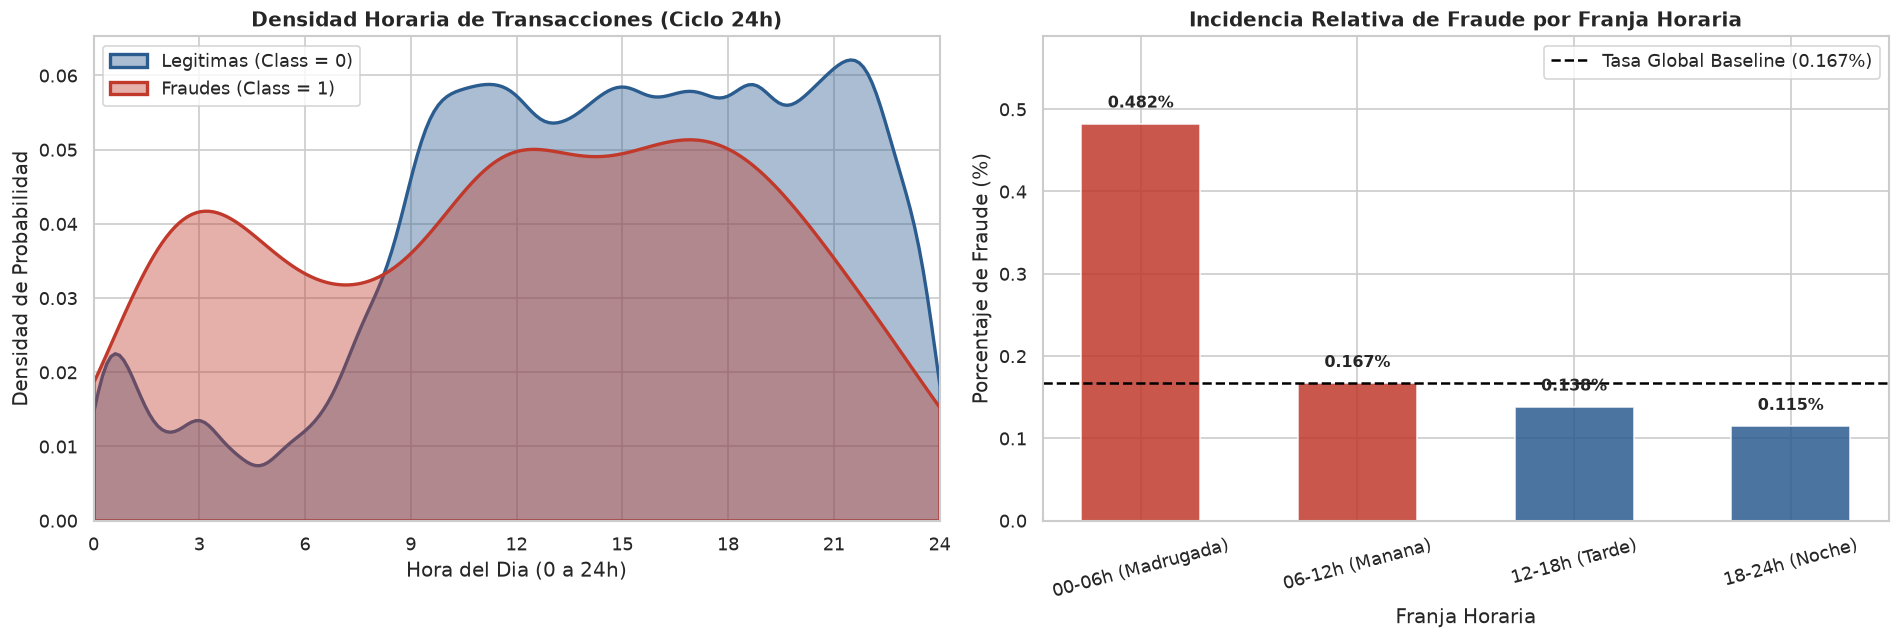

In [11]:
# Visualizacion: Curva de densidad horaria (KDE) + Tasa de fraude por franja
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), dpi=120)

# Panel A: Densidad de probabilidad a lo largo de las 24 horas
sns.kdeplot(
    data=df_temp[df_temp['Class'] == 0], x='Hora_Dia',
    fill=True, color='#2b5c8f', alpha=0.4, linewidth=2,
    label='Legitimas (Class = 0)', ax=axes[0], clip=(0, 24)
)
sns.kdeplot(
    data=df_temp[df_temp['Class'] == 1], x='Hora_Dia',
    fill=True, color='#c0392b', alpha=0.4, linewidth=2,
    label='Fraudes (Class = 1)', ax=axes[0], clip=(0, 24)
)
axes[0].set_title('Densidad Horaria de Transacciones (Ciclo 24h)', fontweight='bold')
axes[0].set_xlabel('Hora del Dia (0 a 24h)')
axes[0].set_ylabel('Densidad de Probabilidad')
axes[0].set_xticks(range(0, 25, 3))
axes[0].set_xlim(0, 24)
axes[0].legend()

# Panel B: Tasa porcentual de fraude por franja horaria
tasa_global = (df_temp['Class'].mean()) * 100
colores_franjas = ['#c0392b' if tasa > tasa_global else '#2b5c8f' for tasa in resumen_franjas['Tasa_Fraude (%)']]

bars = axes[1].bar(
    resumen_franjas.index,
    resumen_franjas['Tasa_Fraude (%)'],
    color=colores_franjas,
    alpha=0.85,
    width=0.55
)
axes[1].axhline(tasa_global, color='black', linestyle='--', linewidth=1.5,
                label=f'Tasa Global Baseline ({tasa_global:.3f}%)')

for bar in bars:
    altura = bar.get_height()
    axes[1].text(
        bar.get_x() + bar.get_width() / 2.0,
        altura + 0.015,
        f"{altura:.3f}%",
        ha='center', va='bottom', fontsize=9.5, fontweight='bold'
    )

axes[1].set_title('Incidencia Relativa de Fraude por Franja Horaria', fontweight='bold')
axes[1].set_xlabel('Franja Horaria')
axes[1].set_ylabel('Porcentaje de Fraude (%)')
axes[1].set_ylim(0, resumen_franjas['Tasa_Fraude (%)'].max() * 1.22)
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/05_eda_temporal_chi2.png", bbox_inches='tight')
plt.show()

### Interpretacion

En la prueba de hipotesis, se observa que el valor de $p$ cae en la zona de significancia, mostrando que la incidencia de fraude depende significativamente de la hora del día. Por lo que **se rechaza la hipotesis nula $H_0$** sobre la independencia. 

Por otro lado, se observa graficamente que la tasa de incidencias de las transacciones fraudulentas son frecuentes en la franja horaria de la media noche a la madrugada (0:00am - 5:00am). Las transacciones legitimas son concurridas durante las horas de la mañana, pero caen drasticamente en las horas de la madrugada.

# Fase 4: Transformacione Ingenieria de Caracteristicas

Partiendo de todos los hallazgos estadisticos obtenidos en la Fase 3, es necesario aplicar dos procesos formales para la transformacion sobre el conjunto depurado para habilitar su uso en modelos de analitica avanzada y algoritmos de aprendizaje automatico.

## Ingenieria de Caracteristicas Temporales

En el ultimo analisis (Comportamiento Ciclico Temporal), se demostro mediante el uso de la prueba $\chi^2$ que la tasa de fraude depende de la hora del dia. No obstante, representar la hora de forma lineal ($0$ a $24$) introduce una discontinuidad artificial entre las $23:59$ y las $00:00$. Es por ello que, para preservar los valores ciclicos, es necesario proyectarlo sobre la hora modular $h = (\text{Time}/3600) \bmod 24$ sobre el círculo unitario:

$$\text{Hour\_sin} = \sin\left(\frac{2\pi h}{24}\right), \qquad \text{Hour\_cos} = \cos\left(\frac{2\pi h}{24}\right)$$

In [12]:
# Ingenieria de caracteristicas temporales (Codificacion ciclica)
df_feat = df.copy()

hora_dia = (df_feat['Time'] / 3600.0) % 24.0
df_feat['Hour_sin'] = np.sin(2.0 * np.pi * hora_dia / 24.0).astype('float32')
df_feat['Hour_cos'] = np.cos(2.0 * np.pi * hora_dia / 24.0).astype('float32')

## Compresión Logaritmica y Escalado Robusto
De igual forma, en los analisis sobre la variable "Amount", se comprobo que la misma posee una asimetria positiva extrema, y una alta proporcion de outliers legitimos y fraudulentos. Una transformacion $z$ no funcionaria, pues se demostro que: la distribucion no sigue una distribucion normal; y, los valores de la media y desviacion estandar se encuentran exorbitados. Es por ello que se aplican dos transformaciones complementarias: 

- Transformacion Logaritmica: $x_{\log} = \ln(1 + \text{Amount})$ para estabilizar la varianza y comprimir la cola derecha.
- Escalado Robusto: Centra los datos en la mediana ($Q_2$) y escala segun el rango intercuartílico ($\text{IQR} = Q_3 - Q_1$), igualando el orden de magnitud de Amount y Time con las componentes PCA ($V_1 \dots V_{28}$) sin distorsionarse por valores extremos:

$$x_{\text{robust}} = \frac{x - Q_2(x)}{Q_3(x) - Q_1(x)}$$

In [13]:
# Compresion logaritmica y Escalado Robusto (RobustScaler)
df_feat['Amount_log'] = np.log1p(df_feat['Amount']).astype('float32')

scaler = RobustScaler()
scaled_vals = scaler.fit_transform(df_feat[['Amount', 'Time']])
df_feat['Amount_robust'] = scaled_vals[:, 0].astype('float32')
df_feat['Time_robust'] = scaled_vals[:, 1].astype('float32')

In [14]:
# Verificacion estadistica antes vs. despues de las transformaciones
cols_comparacion = ['Amount', 'Amount_log', 'Amount_robust', 'Time', 'Time_robust', 'Hour_sin', 'Hour_cos']
resumen_trans = df_feat[cols_comparacion].agg(['mean', 'median', 'std', 'min', 'max', 'skew']).T

print("==== RESUMEN ESTADISTICO POST-TRANSFORMACION ====")
display(resumen_trans.round(4))

==== RESUMEN ESTADISTICO POST-TRANSFORMACION ====


,mean,median,std,min,max,skew
Amount,88.472702,22.0000,250.399399,0.0000,25691.160156,16.9788
Amount_log,3.153800,3.1355,1.657100,0.0000,10.153900,0.1614
Amount_robust,0.924400,0.0000,3.482100,-0.3059,356.962311,16.9788
Time,94811.078125,84692.5000,47481.046875,0.0000,172792.000000,-0.0356
Time_robust,0.118900,0.0000,0.558000,-0.9953,1.035300,-0.0356
Hour_sin,-0.266700,-0.4357,0.628200,-1.0000,1.000000,0.5374
Hour_cos,-0.141000,-0.3123,0.717200,-1.0000,1.000000,0.3066


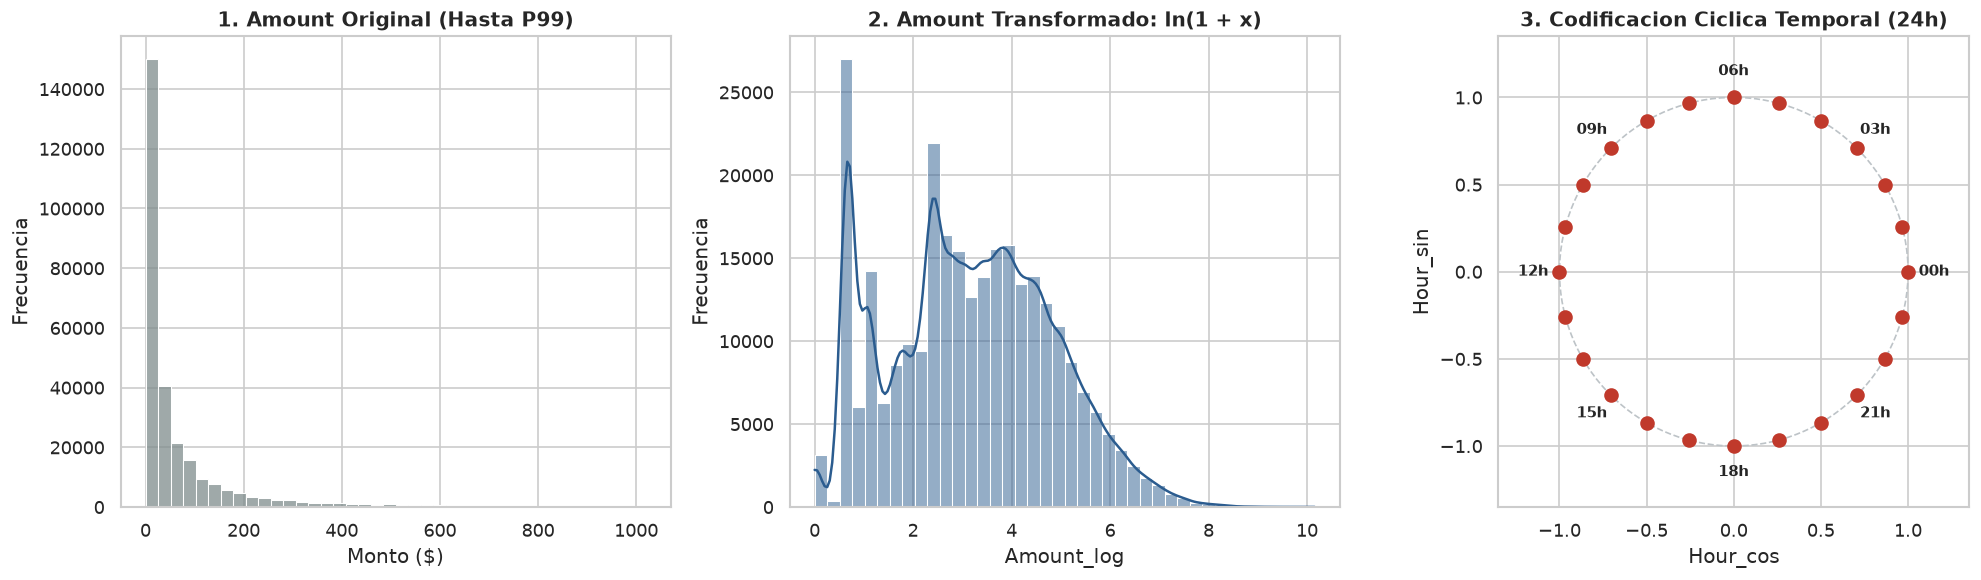


Dataset final transformado guardado en: ../data/processed/transactions_features.parquet
Dimensiones finales: 283,726 filas x 36 columnas


In [15]:
# Visualizacion de impacto: Compresion de asimetria y proyeccion ciclica
fig, axes = plt.subplots(1, 3, figsize=(17, 5), dpi=120)

# Panel A: Amount crudo (recortado a percentil 99 para visualizacion)
p99 = df_feat['Amount'].quantile(0.99)
sns.histplot(df_feat.loc[df_feat['Amount'] <= p99, 'Amount'], bins=40, color='#7f8c8d', ax=axes[0])
axes[0].set_title('1. Amount Original (Hasta P99)', fontweight='bold')
axes[0].set_xlabel('Monto ($)')
axes[0].set_ylabel('Frecuencia')

# Panel B: Amount transformado con log1p
sns.histplot(df_feat['Amount_log'], bins=40, kde=True, color='#2b5c8f', ax=axes[1])
axes[1].set_title('2. Amount Transformado: ln(1 + x)', fontweight='bold')
axes[1].set_xlabel('Amount_log')
axes[1].set_ylabel('Frecuencia')

# Panel C: Proyeccion circular de 24 horas (Hour_sin vs Hour_cos)
horas_unicas = np.arange(0, 24)
sin_vals = np.sin(2.0 * np.pi * horas_unicas / 24.0)
cos_vals = np.cos(2.0 * np.pi * horas_unicas / 24.0)

axes[2].scatter(cos_vals, sin_vals, color='#c0392b', s=60, zorder=3)
circulo = plt.Circle((0, 0), 1.0, color='#bdc3c7', fill=False, linestyle='--')
axes[2].add_patch(circulo)

for h, x_c, y_s in zip(horas_unicas[::3], cos_vals[::3], sin_vals[::3]):
    axes[2].text(x_c * 1.15, y_s * 1.15, f"{h:02d}h", ha='center', va='center', fontsize=9, fontweight='bold')

axes[2].set_title('3. Codificacion Ciclica Temporal (24h)', fontweight='bold')
axes[2].set_xlabel('Hour_cos')
axes[2].set_ylabel('Hour_sin')
axes[2].set_xlim(-1.35, 1.35)
axes[2].set_ylim(-1.35, 1.35)
axes[2].set_aspect('equal')

plt.tight_layout()
plt.savefig("../figures/06_transformacion_features.png", bbox_inches='tight')
plt.show()

# Persistencia del dataset final transformado en formato columnar Parquet
out_dir = "../data/processed"
final_parquet = f"{out_dir}/transactions_features.parquet"
df_feat.to_parquet(final_parquet, index=False, engine="pyarrow")

print(f"\nDataset final transformado guardado en: {final_parquet}")
print(f"Dimensiones finales: {df_feat.shape[0]:,} filas x {df_feat.shape[1]} columnas")

### Resultados de la Transformacion
Al aplicar $\ln(1 + \text{Amount})$, el coeficiente de asimetria cae drasticamente desde $16.98$ (en Amount global) hasta $\approx 0.16$, aproximando la variable a una distribucion simetrica apta para algoritmos parametricos. Mientras que, con *RobustScaler*, tanto ```Amount_robust``` como ```Time_robust``` quedan centradas en 0.0000 (su mediana) con rangos intercuartilicos unitarios ($\text{IQR} = 1$), alineandose con la escala de las variables ortogonales $V_1 \dots V_{28}$.

Finalmente, la codificacion trigonometrica garantiza que la distancia euclidiana entre las 23:00h y las 00:00h sea identica a la distancia entre las 12:00h y las 13:00h, eliminando saltos artificiales de frontera.